# Model Performance Comparison: Empathetic vs Daily Datasets

This notebook performs comprehensive model comparisons:
1. **Empathetic Dataset Comparison** - Ranks models based on performance on empathetic dataset
2. **Daily Dataset Comparison** - Ranks models based on performance on daily dataset
3. **Overall Best Model Selection** - Identifies the best model based on average performance across both datasets

**Primary Metric**: F1 Score (with supporting metrics: Accuracy, Precision, Recall)

In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Dict, List

# Set style for better visualization
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

In [2]:
# Configuration
RESULTS_DIR = './results'
DATASETS = ['empathetic', 'daily']
MODELS = ['distilbert', 'deberta', 'roberta', 'banglabert', 'banglishbert', 'xlnet']
PRIMARY_METRIC = 'F1'  # Primary metric for ranking

## 1. Load Results

In [3]:
def load_all_results(results_dir: str, models: List[str], datasets: List[str]) -> pd.DataFrame:
    """Load all result JSON files into a DataFrame."""
    all_results = []
    
    for dataset in datasets:
        for model in models:
            filename = f"{results_dir}/{model}_{dataset}_results.json"
            if os.path.exists(filename):
                with open(filename, 'r') as f:
                    data = json.load(f)
                    result = {
                        'Model': model,
                        'Dataset': dataset,
                        'Accuracy': data['metrics']['accuracy'],
                        'Precision': data['metrics']['precision'],
                        'Recall': data['metrics']['recall'],
                        'F1': data['metrics']['f1']
                    }
                    all_results.append(result)
            else:
                print(f"⚠️  Warning: {filename} not found")
    
    return pd.DataFrame(all_results)

# Load all results
results_df = load_all_results(RESULTS_DIR, MODELS, DATASETS)
print(f"✅ Loaded {len(results_df)} results from {len(results_df['Model'].unique())} models")
print(f"📊 Datasets: {results_df['Dataset'].unique().tolist()}")
print(f"🤖 Models: {results_df['Model'].unique().tolist()}")

# Display all results
print("\n" + "="*80)
print("ALL RESULTS")
print("="*80)
results_df

✅ Loaded 12 results from 6 models
📊 Datasets: ['empathetic', 'daily']
🤖 Models: ['distilbert', 'deberta', 'roberta', 'banglabert', 'banglishbert', 'xlnet']

ALL RESULTS


,Model,Dataset,Accuracy,Precision,Recall,F1
0,distilbert,empathetic,0.330031,0.326177,0.330031,0.323062
1,deberta,empathetic,0.376316,0.373931,0.376316,0.370769
2,roberta,empathetic,0.372601,0.368810,0.372601,0.366512
3,banglabert,empathetic,0.283437,0.277752,0.283437,0.274554
4,banglishbert,empathetic,0.323839,0.320847,0.323839,0.316290
5,xlnet,empathetic,0.368421,0.365473,0.368421,0.361952
6,distilbert,daily,0.876000,0.876119,0.876000,0.875444
7,deberta,daily,0.874000,0.902038,0.874000,0.885065
8,roberta,daily,0.867000,0.899493,0.867000,0.879780
9,banglabert,daily,0.854000,0.880964,0.854000,0.863094


## 2. Empathetic Dataset Comparison

In [4]:
# Filter and rank by empathetic dataset
empathetic_results = results_df[results_df['Dataset'] == 'empathetic'].copy()
empathetic_results = empathetic_results.sort_values('F1', ascending=False).reset_index(drop=True)
empathetic_results['Rank'] = range(1, len(empathetic_results) + 1)

print("="*80)
print("🔵 EMPATHETIC DATASET - MODEL RANKINGS (by F1 Score)")
print("="*80)
print(empathetic_results[['Rank', 'Model', 'F1', 'Accuracy', 'Precision', 'Recall']].to_string(index=False))

best_empathetic = empathetic_results.iloc[0]
print(f"\n🏆 BEST MODEL FOR EMPATHETIC: {best_empathetic['Model'].upper()}")
print(f"   F1 Score: {best_empathetic['F1']:.4f}")
print(f"   Accuracy: {best_empathetic['Accuracy']:.4f}")
print(f"   Precision: {best_empathetic['Precision']:.4f}")
print(f"   Recall: {best_empathetic['Recall']:.4f}")

🔵 EMPATHETIC DATASET - MODEL RANKINGS (by F1 Score)
 Rank        Model       F1  Accuracy  Precision   Recall
    1      deberta 0.370769  0.376316   0.373931 0.376316
    2      roberta 0.366512  0.372601   0.368810 0.372601
    3        xlnet 0.361952  0.368421   0.365473 0.368421
    4   distilbert 0.323062  0.330031   0.326177 0.330031
    5 banglishbert 0.316290  0.323839   0.320847 0.323839
    6   banglabert 0.274554  0.283437   0.277752 0.283437

🏆 BEST MODEL FOR EMPATHETIC: DEBERTA
   F1 Score: 0.3708
   Accuracy: 0.3763
   Precision: 0.3739
   Recall: 0.3763


## 3. Daily Dataset Comparison

In [5]:
# Filter and rank by daily dataset
daily_results = results_df[results_df['Dataset'] == 'daily'].copy()
daily_results = daily_results.sort_values('F1', ascending=False).reset_index(drop=True)
daily_results['Rank'] = range(1, len(daily_results) + 1)

print("="*80)
print("🟢 DAILY DATASET - MODEL RANKINGS (by F1 Score)")
print("="*80)
print(daily_results[['Rank', 'Model', 'F1', 'Accuracy', 'Precision', 'Recall']].to_string(index=False))

best_daily = daily_results.iloc[0]
print(f"\n🏆 BEST MODEL FOR DAILY: {best_daily['Model'].upper()}")
print(f"   F1 Score: {best_daily['F1']:.4f}")
print(f"   Accuracy: {best_daily['Accuracy']:.4f}")
print(f"   Precision: {best_daily['Precision']:.4f}")
print(f"   Recall: {best_daily['Recall']:.4f}")

🟢 DAILY DATASET - MODEL RANKINGS (by F1 Score)
 Rank        Model       F1  Accuracy  Precision  Recall
    1      deberta 0.885065     0.874   0.902038   0.874
    2 banglishbert 0.883268     0.878   0.890905   0.878
    3      roberta 0.879780     0.867   0.899493   0.867
    4        xlnet 0.876835     0.863   0.899548   0.863
    5   distilbert 0.875444     0.876   0.876119   0.876
    6   banglabert 0.863094     0.854   0.880964   0.854

🏆 BEST MODEL FOR DAILY: DEBERTA
   F1 Score: 0.8851
   Accuracy: 0.8740
   Precision: 0.9020
   Recall: 0.8740


## 4. Overall Best Model Selection (Average Performance)

In [6]:
# Calculate average performance across both datasets
avg_performance = results_df.groupby('Model').agg({
    'F1': 'mean',
    'Accuracy': 'mean',
    'Precision': 'mean',
    'Recall': 'mean'
}).reset_index()

# Add standard deviation to show consistency
std_performance = results_df.groupby('Model').agg({
    'F1': 'std',
    'Accuracy': 'std',
    'Precision': 'std',
    'Recall': 'std'
}).reset_index()

# Rename columns for clarity
avg_performance.columns = ['Model', 'Avg_F1', 'Avg_Accuracy', 'Avg_Precision', 'Avg_Recall']
std_performance.columns = ['Model', 'Std_F1', 'Std_Accuracy', 'Std_Precision', 'Std_Recall']

# Merge and sort by average F1
overall_performance = pd.merge(avg_performance, std_performance, on='Model')
overall_performance = overall_performance.sort_values('Avg_F1', ascending=False).reset_index(drop=True)
overall_performance['Rank'] = range(1, len(overall_performance) + 1)

print("="*100)
print("🌟 OVERALL MODEL RANKINGS (Average Performance Across Both Datasets)")
print("="*100)
print(overall_performance[['Rank', 'Model', 'Avg_F1', 'Std_F1', 'Avg_Accuracy', 'Avg_Precision', 'Avg_Recall']].to_string(index=False))

best_overall = overall_performance.iloc[0]
print(f"\n" + "="*100)
print(f"🥇 OVERALL BEST PERFORMING MODEL: {best_overall['Model'].upper()}")
print("="*100)
print(f"   Average F1 Score: {best_overall['Avg_F1']:.4f} (±{best_overall['Std_F1']:.4f})")
print(f"   Average Accuracy: {best_overall['Avg_Accuracy']:.4f} (±{best_overall['Std_Accuracy']:.4f})")
print(f"   Average Precision: {best_overall['Avg_Precision']:.4f} (±{best_overall['Std_Precision']:.4f})")
print(f"   Average Recall: {best_overall['Avg_Recall']:.4f} (±{best_overall['Std_Recall']:.4f})")
print(f"\n   💡 This model performs consistently well across both empathetic and daily datasets.")
print("="*100)

🌟 OVERALL MODEL RANKINGS (Average Performance Across Both Datasets)
 Rank        Model   Avg_F1   Std_F1  Avg_Accuracy  Avg_Precision  Avg_Recall
    1      deberta 0.627917 0.363662      0.625158       0.637985    0.625158
    2      roberta 0.623146 0.362935      0.619800       0.634152    0.619800
    3        xlnet 0.619393 0.364077      0.615711       0.632511    0.615711
    4 banglishbert 0.599779 0.400914      0.600920       0.605876    0.600920
    5   distilbert 0.599253 0.390592      0.603015       0.601148    0.603015
    6   banglabert 0.568824 0.416161      0.568718       0.579358    0.568718

🥇 OVERALL BEST PERFORMING MODEL: DEBERTA
   Average F1 Score: 0.6279 (±0.3637)
   Average Accuracy: 0.6252 (±0.3519)
   Average Precision: 0.6380 (±0.3734)
   Average Recall: 0.6252 (±0.3519)

   💡 This model performs consistently well across both empathetic and daily datasets.


## 5. Detailed Performance Tables

In [7]:
# Create a pivot table showing all metrics for each model-dataset combination
print("\n" + "="*100)
print("📋 DETAILED PERFORMANCE TABLE - F1 SCORES")
print("="*100)
pivot_f1 = results_df.pivot(index='Model', columns='Dataset', values='F1')
pivot_f1['Average'] = pivot_f1.mean(axis=1)
pivot_f1 = pivot_f1.sort_values('Average', ascending=False)
print(pivot_f1.round(4).to_string())

print("\n" + "="*100)
print("📋 DETAILED PERFORMANCE TABLE - ACCURACY")
print("="*100)
pivot_acc = results_df.pivot(index='Model', columns='Dataset', values='Accuracy')
pivot_acc['Average'] = pivot_acc.mean(axis=1)
pivot_acc = pivot_acc.sort_values('Average', ascending=False)
print(pivot_acc.round(4).to_string())

print("\n" + "="*100)
print("📋 DETAILED PERFORMANCE TABLE - PRECISION")
print("="*100)
pivot_prec = results_df.pivot(index='Model', columns='Dataset', values='Precision')
pivot_prec['Average'] = pivot_prec.mean(axis=1)
pivot_prec = pivot_prec.sort_values('Average', ascending=False)
print(pivot_prec.round(4).to_string())

print("\n" + "="*100)
print("📋 DETAILED PERFORMANCE TABLE - RECALL")
print("="*100)
pivot_rec = results_df.pivot(index='Model', columns='Dataset', values='Recall')
pivot_rec['Average'] = pivot_rec.mean(axis=1)
pivot_rec = pivot_rec.sort_values('Average', ascending=False)
print(pivot_rec.round(4).to_string())


📋 DETAILED PERFORMANCE TABLE - F1 SCORES
Dataset        daily  empathetic  Average
Model                                    
deberta       0.8851      0.3708   0.6279
roberta       0.8798      0.3665   0.6231
xlnet         0.8768      0.3620   0.6194
banglishbert  0.8833      0.3163   0.5998
distilbert    0.8754      0.3231   0.5993
banglabert    0.8631      0.2746   0.5688

📋 DETAILED PERFORMANCE TABLE - ACCURACY
Dataset       daily  empathetic  Average
Model                                   
deberta       0.874      0.3763   0.6252
roberta       0.867      0.3726   0.6198
xlnet         0.863      0.3684   0.6157
distilbert    0.876      0.3300   0.6030
banglishbert  0.878      0.3238   0.6009
banglabert    0.854      0.2834   0.5687

📋 DETAILED PERFORMANCE TABLE - PRECISION
Dataset        daily  empathetic  Average
Model                                    
deberta       0.9020      0.3739   0.6380
roberta       0.8995      0.3688   0.6342
xlnet         0.8995      0.3655   0.6325
b

## 6. Visualizations

### 6.1 Side-by-Side Bar Charts

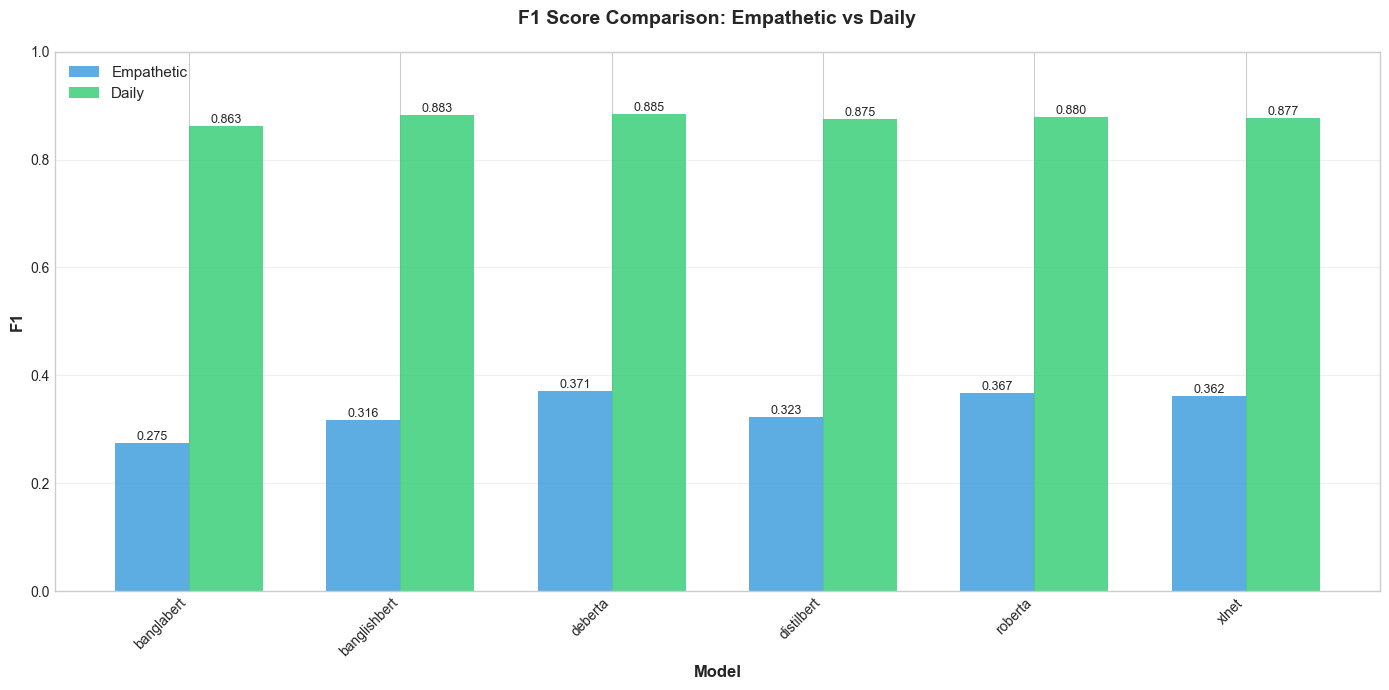

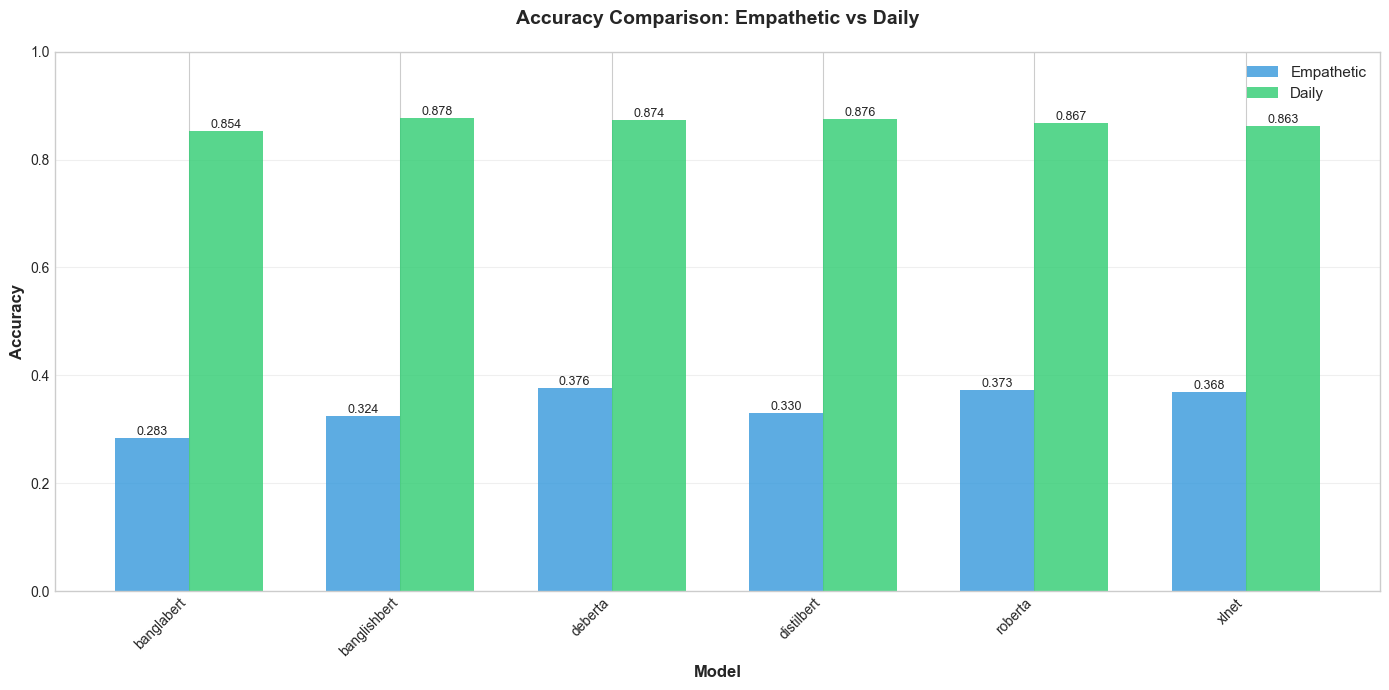

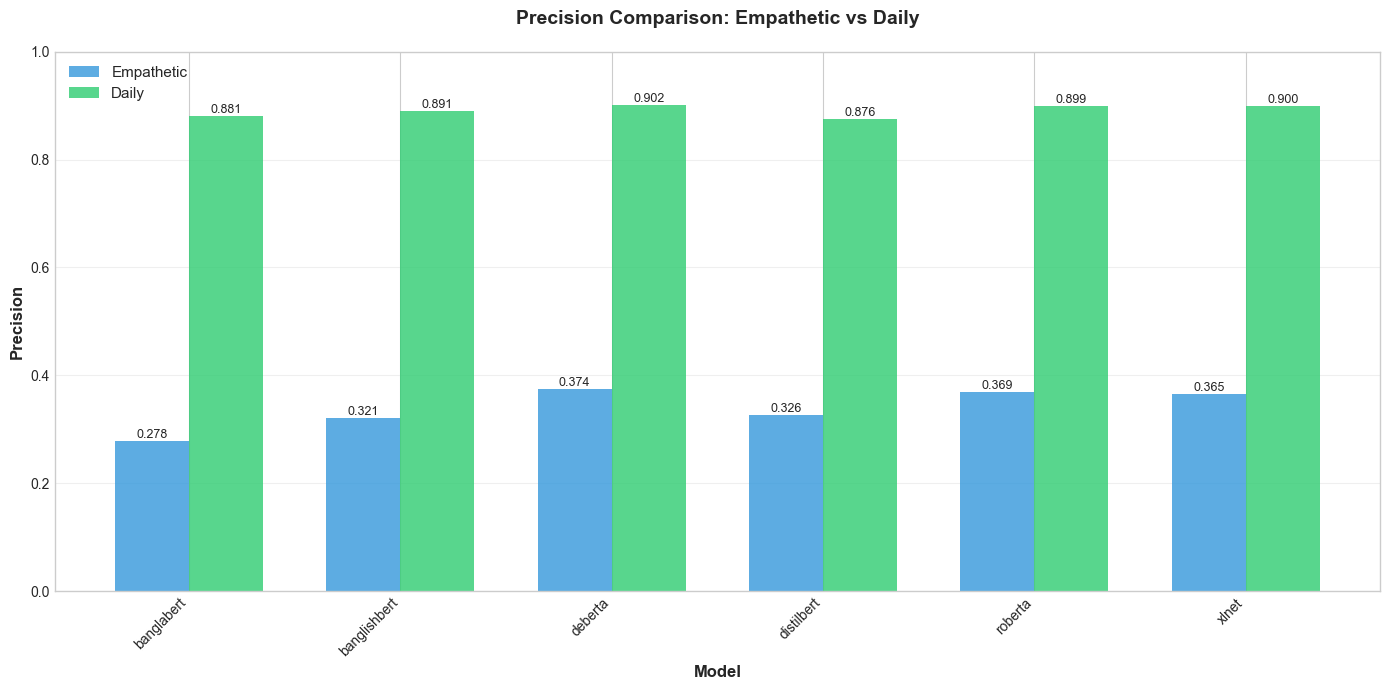

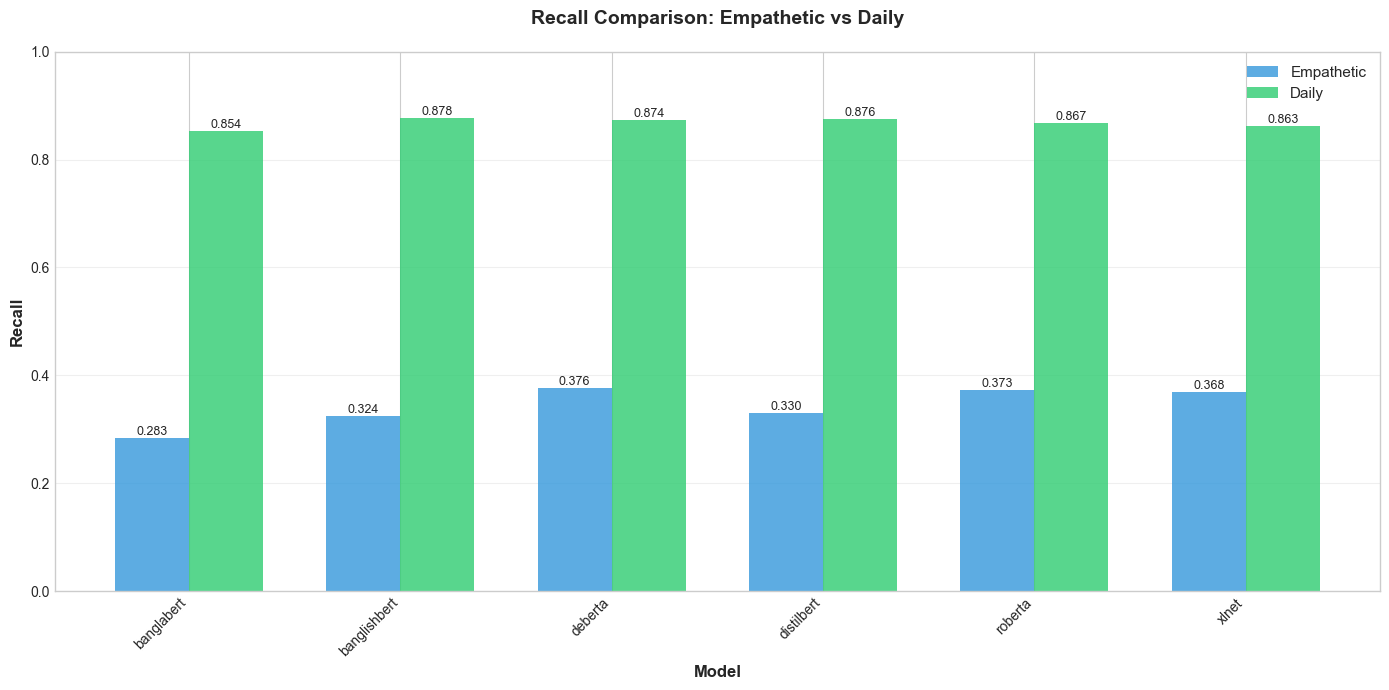

In [8]:
def plot_side_by_side_comparison(df, metric, title):
    """Create side-by-side bar chart comparing models on both datasets."""
    fig, ax = plt.subplots(figsize=(14, 7))
    
    # Pivot for plotting
    pivot = df.pivot(index='Model', columns='Dataset', values=metric)
    
    # Plot grouped bars
    x = np.arange(len(pivot.index))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, pivot['empathetic'], width, label='Empathetic', alpha=0.8, color='#3498db')
    bars2 = ax.bar(x + width/2, pivot['daily'], width, label='Daily', alpha=0.8, color='#2ecc71')
    
    # Customize
    ax.set_xlabel('Model', fontsize=12, fontweight='bold')
    ax.set_ylabel(metric, fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index, rotation=45, ha='right')
    ax.legend(fontsize=11)
    ax.set_ylim(0, 1.0)
    ax.grid(axis='y', alpha=0.3)
    
    # Add value labels
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.3f}',
                   ha='center', va='bottom', fontsize=9, rotation=0)
    
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/{metric.lower()}_sidebyside_comparison.png", dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

# Generate side-by-side comparisons for all metrics
plot_side_by_side_comparison(results_df, 'F1', 'F1 Score Comparison: Empathetic vs Daily')
plot_side_by_side_comparison(results_df, 'Accuracy', 'Accuracy Comparison: Empathetic vs Daily')
plot_side_by_side_comparison(results_df, 'Precision', 'Precision Comparison: Empathetic vs Daily')
plot_side_by_side_comparison(results_df, 'Recall', 'Recall Comparison: Empathetic vs Daily')

### 6.2 Performance Heatmaps

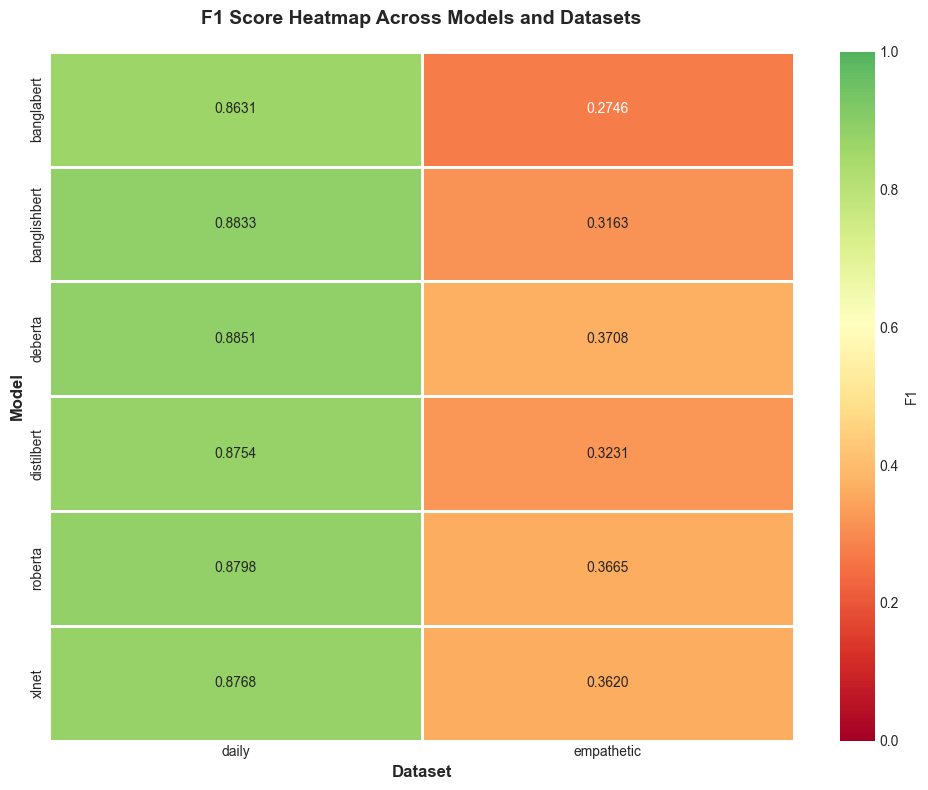

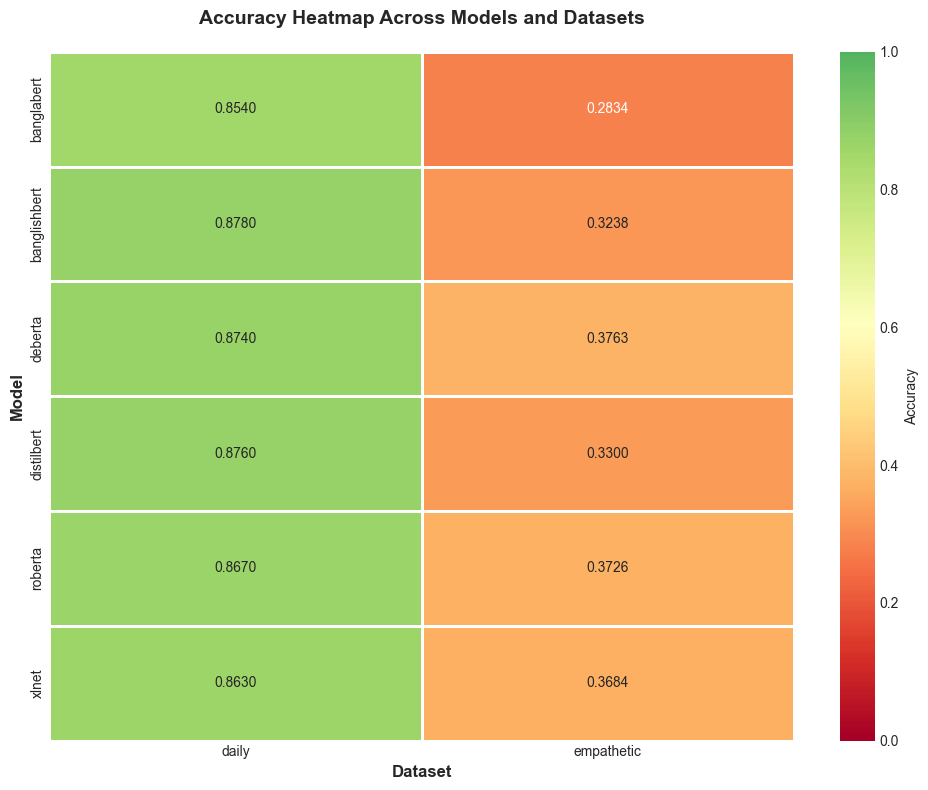

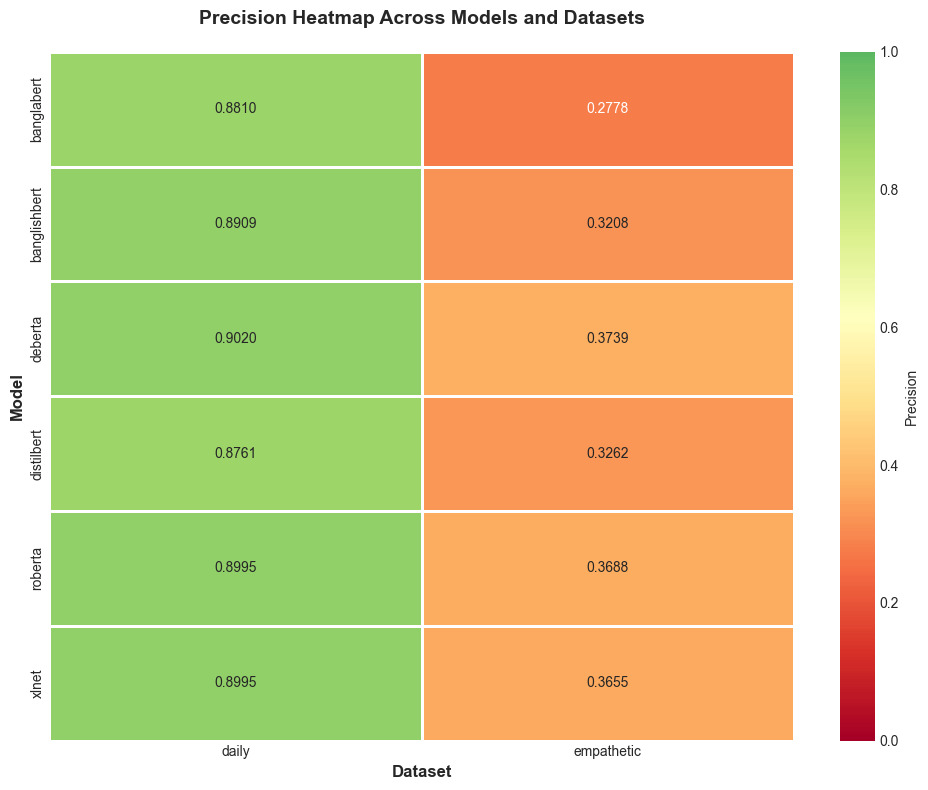

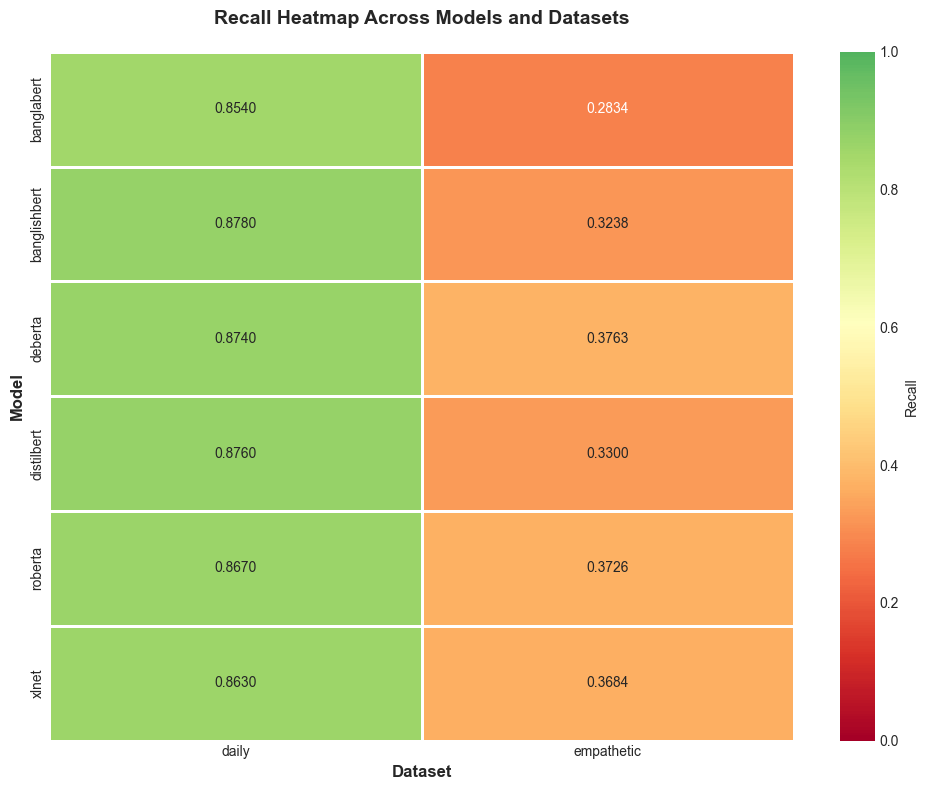

In [9]:
def plot_performance_heatmap(df, metric, title):
    """Create heatmap showing model performance across datasets."""
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Create pivot table
    pivot = df.pivot(index='Model', columns='Dataset', values=metric)
    
    # Create heatmap
    sns.heatmap(pivot, annot=True, fmt='.4f', cmap='RdYlGn', 
                center=pivot.values.mean(), vmin=0, vmax=1,
                cbar_kws={'label': metric}, ax=ax, linewidths=1, linecolor='white')
    
    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
    ax.set_xlabel('Dataset', fontsize=12, fontweight='bold')
    ax.set_ylabel('Model', fontsize=12, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/{metric.lower()}_heatmap.png", dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

# Generate heatmaps for all metrics
plot_performance_heatmap(results_df, 'F1', 'F1 Score Heatmap Across Models and Datasets')
plot_performance_heatmap(results_df, 'Accuracy', 'Accuracy Heatmap Across Models and Datasets')
plot_performance_heatmap(results_df, 'Precision', 'Precision Heatmap Across Models and Datasets')
plot_performance_heatmap(results_df, 'Recall', 'Recall Heatmap Across Models and Datasets')

### 6.3 Radar/Spider Charts for Multi-Metric Analysis

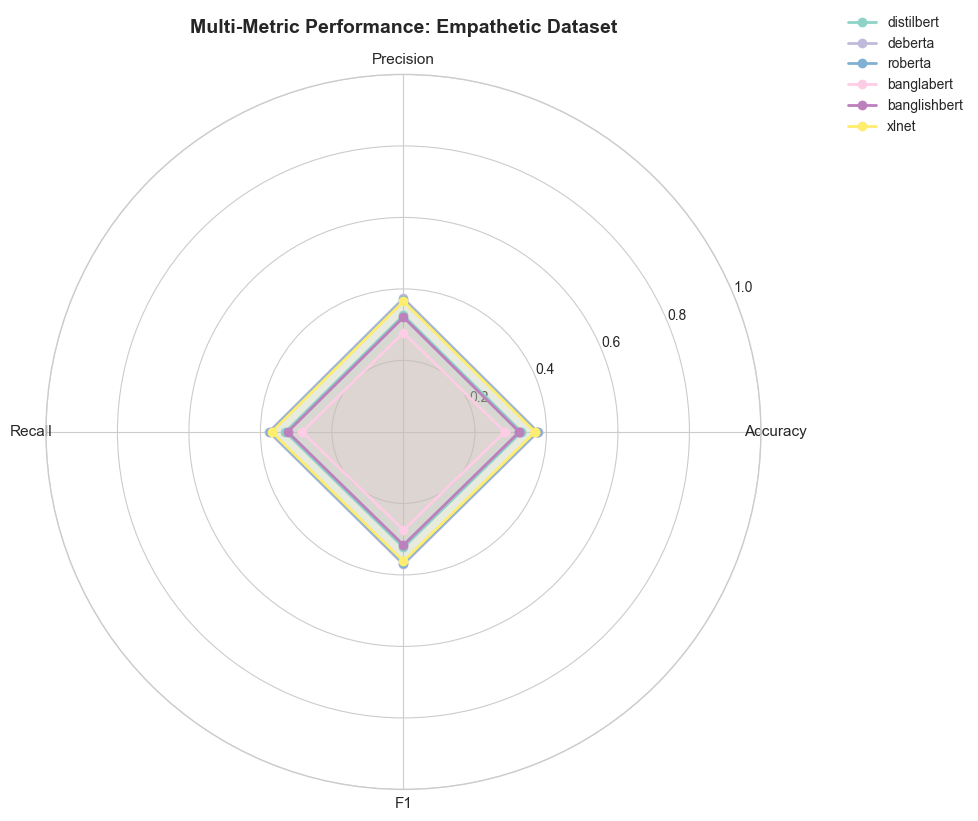

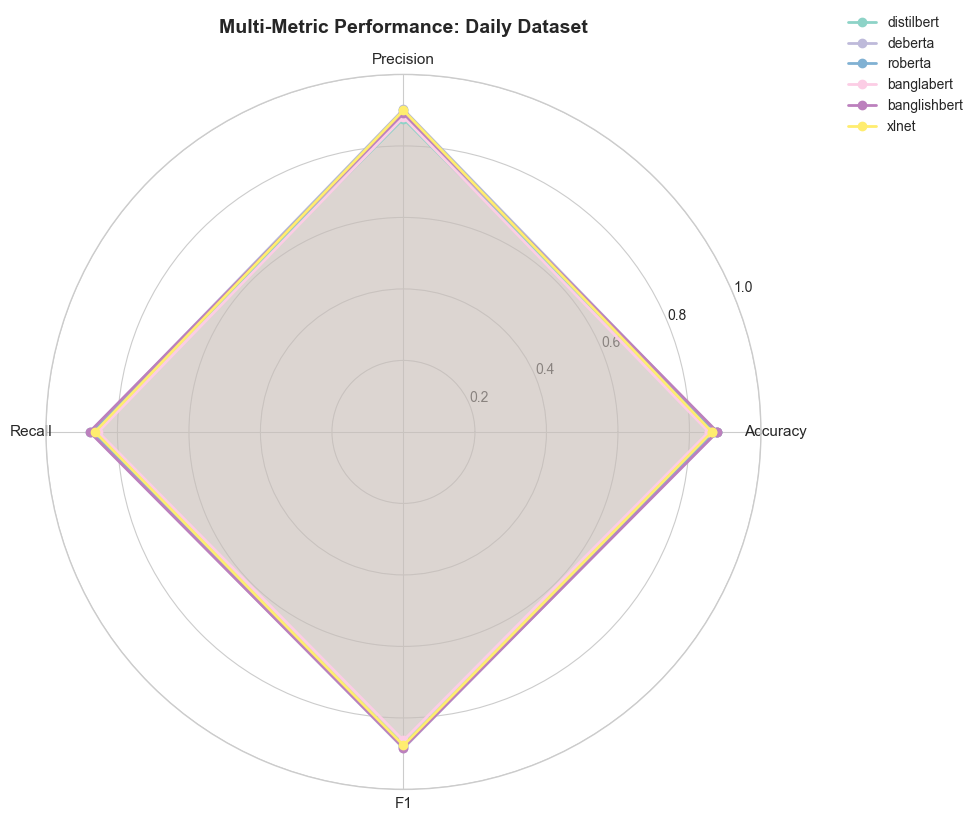

In [10]:
def plot_radar_chart(df, dataset_name, title):
    """Create radar chart showing multi-metric performance for each model on a specific dataset."""
    # Filter by dataset
    dataset_df = df[df['Dataset'] == dataset_name].copy()
    
    # Metrics to plot
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
    num_metrics = len(metrics)
    
    # Calculate angles for each metric
    angles = np.linspace(0, 2 * np.pi, num_metrics, endpoint=False).tolist()
    angles += angles[:1]  # Complete the circle
    
    # Create figure
    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(projection='polar'))
    
    # Plot each model
    colors = plt.cm.Set3(np.linspace(0, 1, len(dataset_df)))
    
    for idx, (_, row) in enumerate(dataset_df.iterrows()):
        values = [row[metric] for metric in metrics]
        values += values[:1]  # Complete the polygon
        
        ax.plot(angles, values, 'o-', linewidth=2, label=row['Model'], color=colors[idx])
        ax.fill(angles, values, alpha=0.15, color=colors[idx])
    
    # Customize
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics, fontsize=11)
    ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=14, fontweight='bold', pad=30)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
    ax.grid(True)
    
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/radar_{dataset_name}.png", dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

# Generate radar charts for each dataset
plot_radar_chart(results_df, 'empathetic', 'Multi-Metric Performance: Empathetic Dataset')
plot_radar_chart(results_df, 'daily', 'Multi-Metric Performance: Daily Dataset')

### 6.4 Average Performance Comparison Bar Chart

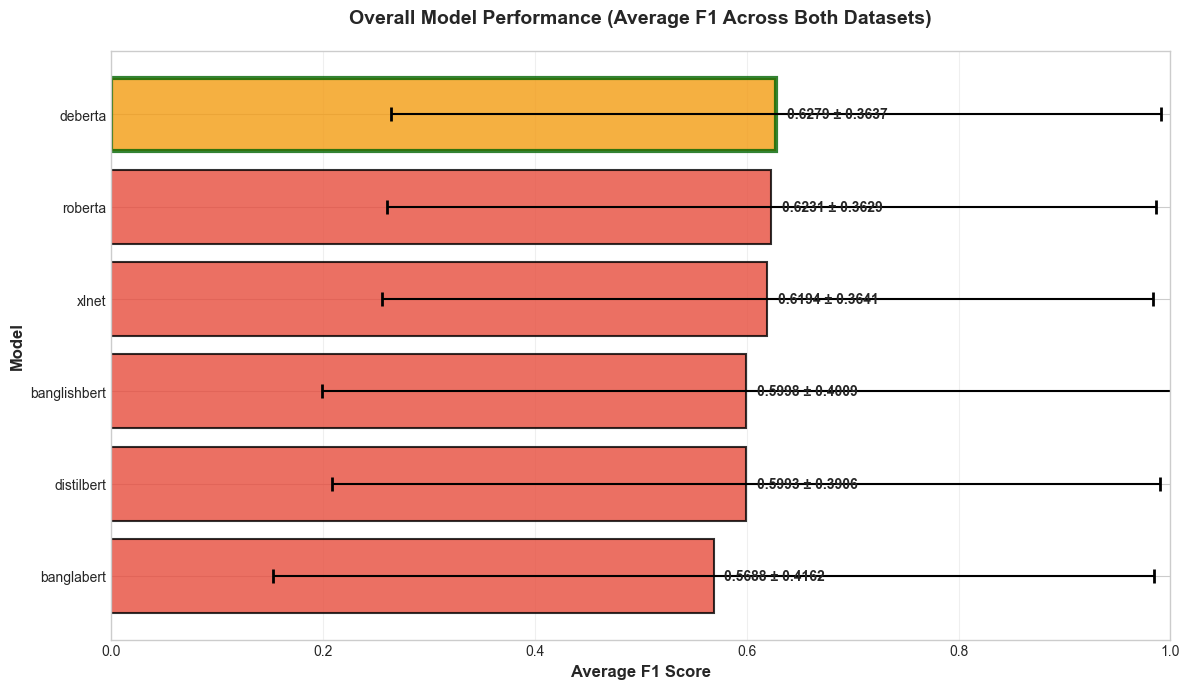

In [11]:
# Plot average performance across both datasets
fig, ax = plt.subplots(figsize=(12, 7))

# Sort by average F1
overall_sorted = overall_performance.sort_values('Avg_F1', ascending=True)

# Create horizontal bar chart
bars = ax.barh(overall_sorted['Model'], overall_sorted['Avg_F1'], 
               color='#e74c3c', alpha=0.8, edgecolor='black', linewidth=1.5)

# Add error bars for standard deviation
ax.errorbar(overall_sorted['Avg_F1'], overall_sorted['Model'], 
            xerr=overall_sorted['Std_F1'], fmt='none', 
            ecolor='black', capsize=5, capthick=2)

# Customize
ax.set_xlabel('Average F1 Score', fontsize=12, fontweight='bold')
ax.set_ylabel('Model', fontsize=12, fontweight='bold')
ax.set_title('Overall Model Performance (Average F1 Across Both Datasets)', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlim(0, 1.0)
ax.grid(axis='x', alpha=0.3)

# Add value labels
for i, (idx, row) in enumerate(overall_sorted.iterrows()):
    ax.text(row['Avg_F1'] + 0.01, i, f"{row['Avg_F1']:.4f} ± {row['Std_F1']:.4f}", 
            va='center', fontsize=10, fontweight='bold')

# Highlight best model
best_idx = overall_sorted['Avg_F1'].idxmax()
best_position = overall_sorted.index.get_loc(best_idx)
bars[best_position].set_color('#f39c12')
bars[best_position].set_edgecolor('darkgreen')
bars[best_position].set_linewidth(3)

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/overall_average_performance.png", dpi=150, bbox_inches='tight')
plt.show()
plt.close()

## 7. Export Results

In [12]:
# Export comprehensive summary to CSV
results_df.to_csv(f"{RESULTS_DIR}/all_results_complete.csv", index=False)
overall_performance.to_csv(f"{RESULTS_DIR}/overall_rankings.csv", index=False)
empathetic_results.to_csv(f"{RESULTS_DIR}/empathetic_rankings.csv", index=False)
daily_results.to_csv(f"{RESULTS_DIR}/daily_rankings.csv", index=False)

print("✅ Results exported:")
print(f"   - {RESULTS_DIR}/all_results_complete.csv")
print(f"   - {RESULTS_DIR}/overall_rankings.csv")
print(f"   - {RESULTS_DIR}/empathetic_rankings.csv")
print(f"   - {RESULTS_DIR}/daily_rankings.csv")

✅ Results exported:
   - ./results/all_results_complete.csv
   - ./results/overall_rankings.csv
   - ./results/empathetic_rankings.csv
   - ./results/daily_rankings.csv
